In [19]:
!pip install kagglehub


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


# 흉부 X-ray 분류 실험

**질문:** 사전 학습이 없는 모델은 사전 학습이 있는 모델과 어떤 차이를 낼까?

# 데이터 불러오기

In [20]:
import sys
import os
from pathlib import Path
import torch
import torch.nn as nn
import pandas as pd
import kagglehub
from torchvision import datasets
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from collections import Counter

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src').exists():
    raise RuntimeError('프로젝트 루트 또는 notebooks 폴더에서 실행하세요.')
sys.path.insert(0, str(PROJECT_ROOT))
from src.data import make_loaders
from src.model import create_model
from src.experiment import load_or_train
from src.evaluate import evaluate, plot_confusion_matrix, plot_loss_history


In [21]:
# Download latest version
dataset_root = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Dataset path:", dataset_root)

Dataset path: /Users/yundong-ug/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2


In [22]:
# GPU 설정
device = torch.device("mps" if torch.mps.is_available() else "cpu")
print(device)

mps


In [23]:
train_dir = os.path.join(dataset_root, "chest_xray", "train")
val_dir = os.path.join(dataset_root, "chest_xray", "val")
test_dir = os.path.join(dataset_root, "chest_xray", "test")

# 1. 데이터 점검: 데이터가 어떤 상태인가?

In [24]:
train_dataset = datasets.ImageFolder(train_dir)

## 1.1 첫번째로 존재하는 이미지 사이즈 확인하기
`train_dataset.samples[0]` => 2090 x 1858

In [25]:
image_path, label = train_dataset.samples[0]

with Image.open(image_path) as img:
    print(image_path)
    print(img.size)  # (가로 픽셀, 세로 픽셀)

/Users/yundong-ug/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/train/NORMAL/IM-0115-0001.jpeg
(2090, 1858)


## 1.2 이미지의 사이즈는 다양할까? 다양하다면 어디에 제일 많이 몰려 있을까?

In [26]:
sizes = Counter()
for image_path, _ in train_dataset.samples:
    with Image.open(image_path) as img:
        sizes[img.size] += 1

train_data_size_table = pd.DataFrame(
    [(width, height, count) for (width, height), count in sizes.items()],
    columns=["width", "height", "count"]
).sort_values("count", ascending=False).reset_index(drop=True)

In [27]:
train_data_size_table.describe()

,width,height,count
count,4366.000000,4366.000000,4366.000000
mean,1354.620705,1005.840357,1.194686
std,369.080580,394.074698,0.536954
min,384.000000,127.000000,1.000000
25%,1080.000000,712.000000,1.000000
50%,1336.000000,955.000000,1.000000
75%,1600.000000,1248.000000,1.000000
max,2916.000000,2663.000000,7.000000


1000~1500 x 500~1000 이 구간대의 사이즈를 가진 이미지가 가장 많다.

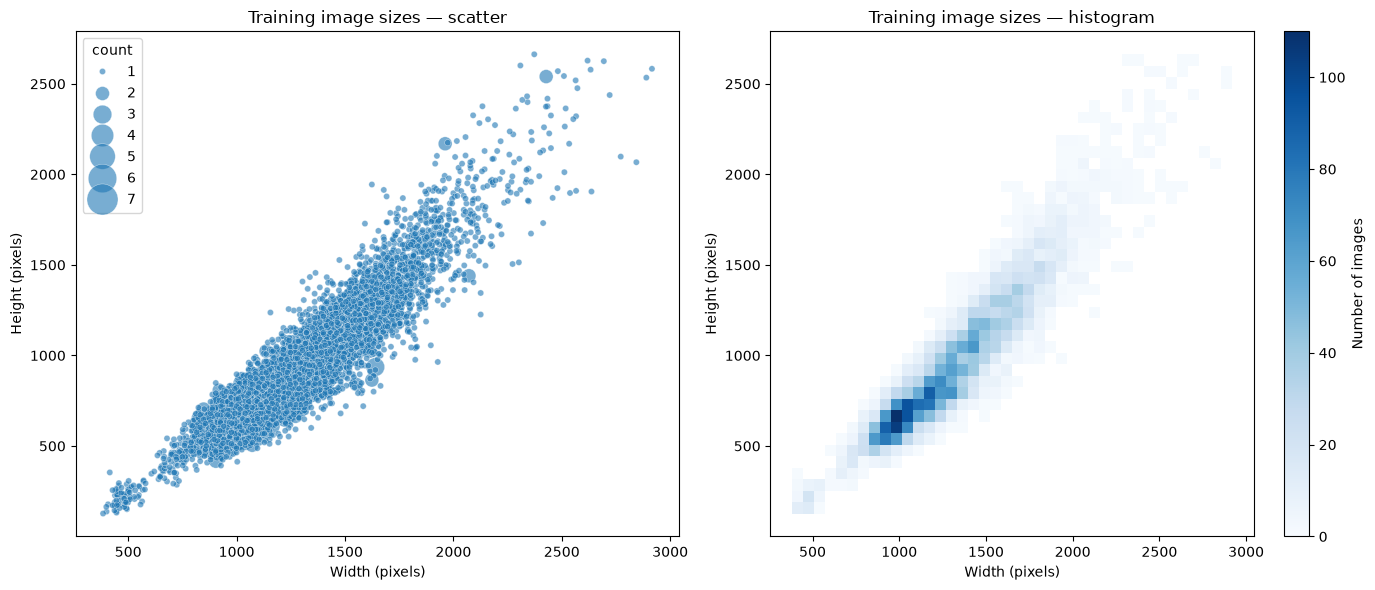

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.scatterplot(
    data=train_data_size_table,
    x="width",
    y="height",
    size="count",
    sizes=(20, 500),
    alpha=0.6,
    legend="brief",
    ax=axes[0],
)

axes[0].set_title("Training image sizes — scatter")
axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Height (pixels)")

sns.histplot(
    data=train_data_size_table,
    x="width",
    y="height",
    weights="count",
    bins=40,
    cmap="Blues",
    cbar=True,
    cbar_kws={"label": "Number of images"},
    ax=axes[1],
)
axes[1].set_title("Training image sizes — histogram")
axes[1].set_xlabel("Width (pixels)")
axes[1].set_ylabel("Height (pixels)")

fig.tight_layout()
plt.show()

## 1.3 베이스 라인 찍기: 클래스 비율로 찍어도 이정도는 나오지 않을까?

PNEUMONIA 클래스: 74.3%

In [29]:
class_counts = (
    pd.Series(train_dataset.targets)
    .map(dict(enumerate(train_dataset.classes)))
    .value_counts()
)

class_table = pd.DataFrame({
    "class": class_counts.index,
    "count": class_counts.values,
    "percent": class_counts.values / class_counts.sum() * 100
})

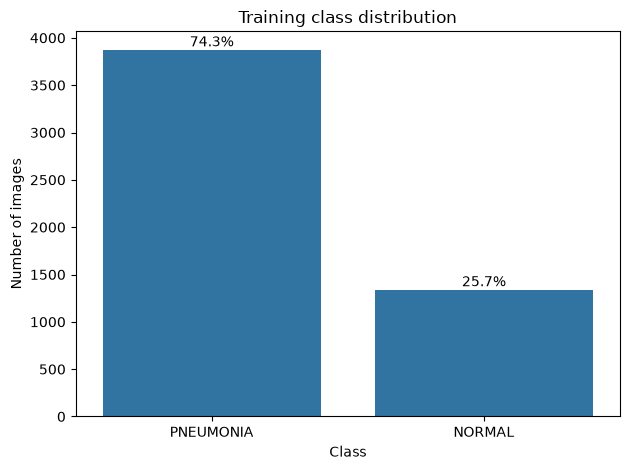

In [30]:
ax = sns.barplot(data=class_table, x="class", y="count")

for bar, percent in zip(ax.patches, class_table["percent"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percent:.1f}%",
        ha="center",
        va="bottom"
    )

ax.set(xlabel="Class", ylabel="Number of images", title="Training class distribution")
plt.tight_layout()
plt.show()

## 2. 환자 단위 검증셋 재구성

원래 train과 작은 val을 합친 뒤 파일명에서 환자 ID를 추출하여 `StratifiedGroupKFold`로 약 80:20 분리한다. 같은 환자는 train과 validation 양쪽에 들어가지 않는다. 클래스 비율을 확인하고 분할 seed를 고정한다. 제공된 test는 분할에 참여하지 않는다.


In [31]:
SEED = 42
BATCH_SIZE = 32
EPOCHS = 10
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print('device:', device)

# scratch 모델용 전처리
scratch_data = make_loaders(dataset_root, batch_size=BATCH_SIZE, seed=SEED, augment=False, pretrained=False)
class_names = scratch_data['classes']
print('classes:', class_names, 'sizes:', scratch_data['sizes'])
print('split:', scratch_data['split'])
# 다수 클래스로만 예측했을 때의 기준 정확도
raw_train = datasets.ImageFolder(train_dir)
raw_val = datasets.ImageFolder(val_dir)
all_targets = raw_train.targets + raw_val.targets
majority_baseline = max(Counter(all_targets).values()) / len(all_targets)
print('majority-class baseline:', round(majority_baseline, 3))


device: mps
classes: ['NORMAL', 'PNEUMONIA'] sizes: {'train': 4185, 'val': 1047, 'test': 624}
split: {'strategy': 'stratified_patient_group', 'seed': 42, 'train_patients': 2288, 'val_patients': 573, 'patient_overlap': 0}
majority-class baseline: 0.742


### 2.1 Train과 validation에 완전히 같은 파일이 있는가?

SHA-256으로 **파일 내용이 완전히 같은 경우**만 찾는다. 중복이 있으면 훈련셋은 유지하고 검증셋에서만 제외한다. 파일명이 다른 동일 파일도 탐지할 수 있지만, 리사이즈·재인코딩된 유사 이미지는 이 방법으로 탐지하지 못한다.


In [32]:
import hashlib
from torch.utils.data import DataLoader, Subset

def sha256_file(file_path):
    digest = hashlib.sha256()
    with open(file_path, 'rb') as image_file:
        for chunk in iter(lambda: image_file.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def sample_path(subset, index):
    # Subset(ConcatDataset([original_train, original_val])) 구조에서 경로 찾기
    sources = subset.dataset.datasets
    if index < len(sources[0]):
        return sources[0].samples[index][0]
    return sources[1].samples[index - len(sources[0])][0]

train_subset = scratch_data['train'].dataset
val_subset = scratch_data['val'].dataset
train_hashes = {}
for index in train_subset.indices:
    image_path = sample_path(train_subset, index)
    train_hashes.setdefault(sha256_file(image_path), image_path)

kept_val_indices = []
duplicate_pairs = []
for index in val_subset.indices:
    image_path = sample_path(val_subset, index)
    digest = sha256_file(image_path)
    if digest in train_hashes:
        duplicate_pairs.append((train_hashes[digest], image_path))
    else:
        kept_val_indices.append(index)

print(f"train/validation 중복: {len(duplicate_pairs)}개")
if duplicate_pairs:
    display(pd.DataFrame(duplicate_pairs, columns=['train_path', 'val_path']))
    if not kept_val_indices:
        raise ValueError('중복 제거 후 validation이 비어 있습니다.')
    scratch_data['val'] = DataLoader(
        Subset(val_subset.dataset, kept_val_indices),
        batch_size=scratch_data['val'].batch_size, shuffle=False,
        num_workers=scratch_data['val'].num_workers,
    )
    scratch_data['sizes']['val'] = len(kept_val_indices)
print('필터링 후 validation:', scratch_data['sizes']['val'])


train/validation 중복: 0개
필터링 후 validation: 1047


In [33]:
# 이전 셀에서 찾은 동일 파일 쌍을 나란히 확인한다.
max_pairs_to_show = 8
if duplicate_pairs:
    shown_pairs = duplicate_pairs[:max_pairs_to_show]
    fig, axes = plt.subplots(len(shown_pairs), 2, figsize=(10, 4 * len(shown_pairs)), squeeze=False)
    for row, (train_path, val_path) in enumerate(shown_pairs):
        for col, image_path in enumerate((train_path, val_path)):
            with Image.open(image_path) as image:
                axes[row, col].imshow(image, cmap='gray')
            axes[row, col].set_title(f"{'train' if col == 0 else 'validation'}: {Path(image_path).name}")
            axes[row, col].axis('off')
    plt.tight_layout()
    plt.show()
    if len(duplicate_pairs) > max_pairs_to_show:
        print(f"나머지 {len(duplicate_pairs) - max_pairs_to_show}쌍은 경로 표에서 확인하세요.")
else:
    print('파일 내용이 완전히 같은 train/validation 이미지는 없습니다.')


파일 내용이 완전히 같은 train/validation 이미지는 없습니다.


## 작은 CNN 기준 모델

사전 학습 없이 훈련한 모델을 기준으로 삼는다. 검증셋에서 오류를 분석한 뒤 증강 또는 모델 구조 실험으로 이어간다.

각 에폭의 train/validation loss·accuracy·precision·recall·F1·혼동 행렬은 `outputs/experiments/`의 CSV에 저장한다. Precision, Recall, F1의 양성 클래스는 `PNEUMONIA`이다.


In [34]:
# %%script false --no-raise-error
torch.manual_seed(SEED)
criterion = nn.CrossEntropyLoss()
scratch_model, scratch_history, scratch_reused = load_or_train(
    'custom_cnn', num_classes=len(class_names), pretrained=False, mode='full',
    train_loader=scratch_data['train'], val_loader=scratch_data['val'],
    criterion=criterion, device=device, epochs=EPOCHS, lr=1e-3, seed=SEED,
    output_dir=PROJECT_ROOT / 'outputs' / 'experiments',
)
print('기존 실험 재사용:', scratch_reused)


Reused custom_cnn: best epoch 9, val recall 0.997, LR 0.001
기존 실험 재사용: True


,epoch,train_loss,train_accuracy,train_precision,train_recall,train_f1,train_confusion_matrix,train_tn,train_fp,train_fn,...,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_confusion_matrix,val_tn,val_fp,val_fn,val_tp
0,1,0.268507,0.887216,0.896448,0.958789,0.926571,"[[735, 344], [128, 2978]]",735.0,344.0,128.0,...,0.159823,0.935053,0.937115,0.978121,0.957179,"[[219, 51], [17, 760]]",219.0,51.0,17.0,760.0
1,2,0.142341,0.945281,0.960910,0.965551,0.963225,"[[957, 122], [107, 2999]]",957.0,122.0,107.0,...,0.116489,0.956065,0.955168,0.987130,0.970886,"[[234, 36], [10, 767]]",234.0,36.0,10.0,767.0
2,3,0.117375,0.955556,0.968850,0.971346,0.970096,"[[982, 97], [89, 3017]]",982.0,97.0,89.0,...,0.094364,0.961796,0.976714,0.971686,0.974194,"[[252, 18], [22, 755]]",252.0,18.0,22.0,755.0
3,4,0.095090,0.966308,0.977456,0.977141,0.977298,"[[1009, 70], [71, 3035]]",1009.0,70.0,71.0,...,0.088902,0.967526,0.988173,0.967825,0.977893,"[[261, 9], [25, 752]]",261.0,9.0,25.0,752.0
4,5,0.091307,0.966308,0.975923,0.978751,0.977335,"[[1004, 75], [66, 3040]]",1004.0,75.0,66.0,...,0.129233,0.950334,0.993197,0.939511,0.965608,"[[265, 5], [47, 730]]",265.0,5.0,47.0,730.0
5,6,0.083421,0.971804,0.981625,0.980361,0.980992,"[[1022, 57], [61, 3045]]",1022.0,57.0,61.0,...,0.089700,0.961796,0.958904,0.990991,0.974684,"[[237, 33], [7, 770]]",237.0,33.0,7.0,770.0
6,7,0.083136,0.967742,0.977499,0.979073,0.978285,"[[1009, 70], [65, 3041]]",1009.0,70.0,65.0,...,0.082144,0.969436,0.968553,0.990991,0.979644,"[[245, 25], [7, 770]]",245.0,25.0,7.0,770.0
7,8,0.074470,0.972282,0.981637,0.981005,0.981320,"[[1022, 57], [59, 3047]]",1022.0,57.0,59.0,...,0.067607,0.975167,0.978344,0.988417,0.983355,"[[253, 17], [9, 768]]",253.0,17.0,9.0,768.0
8,9,0.075524,0.970609,0.980664,0.979717,0.980190,"[[1019, 60], [63, 3043]]",1019.0,60.0,63.0,...,0.094560,0.957020,0.947433,0.997426,0.971787,"[[227, 43], [2, 775]]",227.0,43.0,2.0,775.0
9,10,0.067109,0.975388,0.984199,0.982614,0.983406,"[[1030, 49], [54, 3052]]",1030.0,49.0,54.0,...,0.064623,0.972302,0.974619,0.988417,0.981470,"[[250, 20], [9, 768]]",250.0,20.0,9.0,768.0


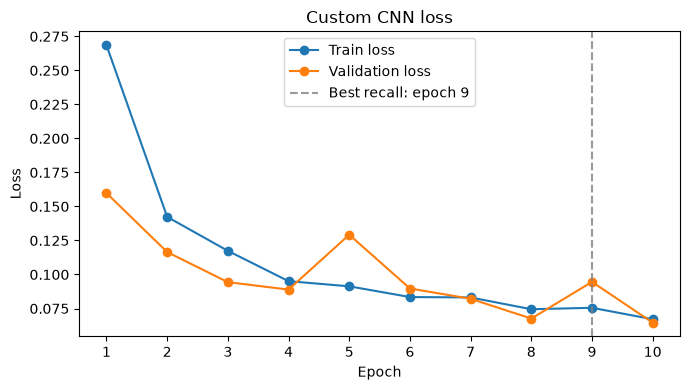

              precision    recall  f1-score     support
NORMAL         0.991266  0.840741  0.909820   270.00000
PNEUMONIA      0.947433  0.997426  0.971787   777.00000
accuracy       0.957020  0.957020  0.957020     0.95702
macro avg      0.969350  0.919083  0.940803  1047.00000
weighted avg   0.958737  0.957020  0.955807  1047.00000


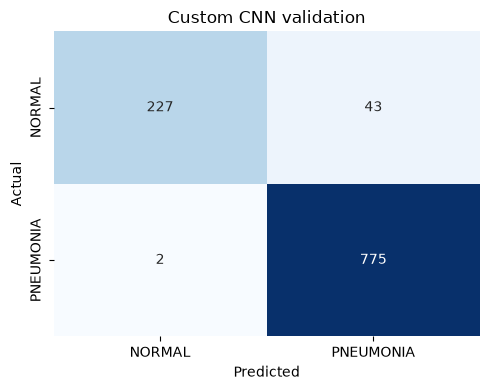

In [35]:
display(pd.DataFrame(scratch_history))
plot_loss_history(scratch_history, 'Custom CNN loss')
plt.show()
scratch_val = evaluate(scratch_model, scratch_data['val'], criterion, device, class_names)
print(pd.DataFrame(scratch_val['report']).T)
plot_confusion_matrix(scratch_val['confusion_matrix'], class_names, 'Custom CNN validation')
plt.show()

# 3. 모델 구조 비교

## 구조만 바꾸면 결과가 달라지는가?

직접 구현한 AlexNet·VGG16·GoogLeNet·ResNet18을 **사전 학습 없이 랜덤 초기화**하여 비교한다. 데이터 분할, 전처리, batch size, epoch, 손실 함수, optimizer와 learning rate는 Custom CNN 실험과 동일하게 고정한다. 네 비교 모델은 별도 seed generator를 사용해 epoch별 데이터 셔플 순서도 같게 맞춘다. 이미 학습한 Custom CNN 결과는 기준값으로 함께 표시한다.

모델 구현은 `src/models/`에 있으며 `create_model(..., pretrained=False, mode='full')`로 생성한다. 각 모델은 검증 후 CPU로 옮겨 GPU/MPS 메모리를 비우고, 완료된 동일 설정의 실험은 `outputs/experiments/`에서 재사용한다.

|	|parameters_million|best_epoch|accuracy|precision|recall|f1|reused|
|---|---|---|---|---|---|---|---|
|model|							
VGG16|	134.27|	10|	0.9102	|0.8921	|1.0000	|0.9430	|False
ResNet18|	11.18|	5|	0.8644|	0.8455|	1.0000|	0.9163|	False
GoogLeNet|	5.98|	1|	0.8090|	0.7953|	1.0000|	0.8860|	False
Custom CNN|	0.42|	9|	0.9570	|0.9474|	0.9974|	0.9718|	True
AlexNet|	57.01|	10	|0.9704|	0.9686	|0.9923|	0.9803|	False


In [36]:
# 화면에 표시할 이름과 모델 생성 함수에 전달할 모델 키를 연결한다.
scratch_architectures = {
    'AlexNet': 'alexnet',
    'VGG16': 'vgg16',
    'GoogLeNet': 'googlenet',
    'ResNet18': 'resnet18',
}

# 모델별 학습 곡선과 최종 검증 지표를 모아 마지막 셀에서 비교한다.
# Custom CNN은 바로 위 셀에서 이미 학습·평가했으므로 기존 결과를 재사용한다.
architecture_histories = {'Custom CNN': scratch_history}
comparison_rows = []

def make_seeded_train_loader(base_loader, seed):
    # 전용 generator를 사용해 모든 비교 모델의 데이터 셔플 순서를 동일하게 만든다.
    # 모델 초기화/Dropout의 전역 RNG와 DataLoader의 셔플 RNG도 서로 분리된다.
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(
        base_loader.dataset,
        batch_size=base_loader.batch_size,
        shuffle=True,
        num_workers=base_loader.num_workers,
        collate_fn=base_loader.collate_fn,
        pin_memory=base_loader.pin_memory,
        drop_last=base_loader.drop_last,
        generator=generator,
    )

def add_comparison_row(model_label, model, history, validation, reused):
    # 체크포인트 선택 기준과 동일하게 Recall → F1 → 낮은 loss 순으로 최고 epoch를 찾는다.
    best_epoch = max(
        history,
        key=lambda row: (row['val_recall'], row['val_f1'], -row['val_loss']),
    )['epoch']
    # 모델 크기와 최고 가중치의 검증 성능을 비교표의 한 행으로 저장한다.
    comparison_rows.append({
        'model': model_label,
        'parameters_million': sum(p.numel() for p in model.parameters()) / 1_000_000,
        'best_epoch': best_epoch,
        'accuracy': validation['accuracy'],
        'precision': validation['precision'],
        'recall': validation['recall'],
        'f1': validation['f1'],
        'reused': reused,
    })

# 기존 Custom CNN을 기준 행으로 먼저 추가한다.
add_comparison_row(
    'Custom CNN', scratch_model, scratch_history, scratch_val, scratch_reused
)
# 더 큰 모델을 학습할 공간을 확보하기 위해 Custom CNN을 CPU로 옮긴다.
scratch_model.to('cpu')
if device.type == 'cuda':
    torch.cuda.empty_cache()
elif device.type == 'mps' and hasattr(torch.mps, 'empty_cache'):
    torch.mps.empty_cache()

# 네 가지 구조를 동일한 학습 조건으로 하나씩 학습하고 검증한다.
for model_label, model_name in scratch_architectures.items():
    # 각 모델의 랜덤 가중치 초기화가 재현되도록 같은 seed에서 시작한다.
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    # pretrained=False이므로 사전 학습 가중치 없이 처음부터 학습한다.
    # 동일 설정의 완료된 실험이 있으면 체크포인트와 history를 재사용한다.
    compared_model, history, reused = load_or_train(
        model_name, num_classes=len(class_names), pretrained=False, mode='full',
        train_loader=make_seeded_train_loader(scratch_data['train'], SEED),
        val_loader=scratch_data['val'],
        criterion=criterion, device=device, epochs=EPOCHS, lr=1e-3, seed=SEED,
        output_dir=PROJECT_ROOT / 'outputs' / 'experiments',
    )
    # 학습 중 선택된 최고 가중치를 동일한 validation 데이터로 평가한다.
    validation = evaluate(
        compared_model, scratch_data['val'], criterion, device, class_names
    )
    # 에폭별 기록은 곡선용으로, 최종 지표는 비교표용으로 저장한다.
    architecture_histories[model_label] = history
    add_comparison_row(model_label, compared_model, history, validation, reused)
    print(
        f"{model_label}: reused={reused}, "
        f"accuracy={validation['accuracy']:.4f}, "
        f"recall={validation['recall']:.4f}, f1={validation['f1']:.4f}"
    )

    # 여러 대형 모델이 GPU/MPS에 동시에 남지 않도록 다음 반복 전에 정리한다.
    compared_model.to('cpu')
    del compared_model
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    elif device.type == 'mps' and hasattr(torch.mps, 'empty_cache'):
        torch.mps.empty_cache()

Epoch 1/10 | train loss 0.5034, acc 0.752, P/R/F1 0.787/0.911/0.845 | val loss 0.3255, acc 0.849, P/R/F1 0.942/0.849/0.893
Epoch 2/10 | train loss 0.2628, acc 0.894, P/R/F1 0.928/0.929/0.929 | val loss 0.1748, acc 0.943, P/R/F1 0.946/0.978/0.962
Epoch 3/10 | train loss 0.1901, acc 0.923, P/R/F1 0.953/0.943/0.948 | val loss 0.1248, acc 0.954, P/R/F1 0.960/0.979/0.969
Epoch 4/10 | train loss 0.1423, acc 0.950, P/R/F1 0.967/0.966/0.966 | val loss 0.1491, acc 0.945, P/R/F1 0.984/0.941/0.962
Epoch 5/10 | train loss 0.1283, acc 0.951, P/R/F1 0.969/0.965/0.967 | val loss 0.1617, acc 0.952, P/R/F1 0.968/0.968/0.968
Epoch 6/10 | train loss 0.1209, acc 0.958, P/R/F1 0.977/0.967/0.972 | val loss 0.1085, acc 0.958, P/R/F1 0.966/0.978/0.972
Epoch 7/10 | train loss 0.1406, acc 0.948, P/R/F1 0.969/0.961/0.965 | val loss 0.0908, acc 0.968, P/R/F1 0.979/0.978/0.979
Epoch 8/10 | train loss 0.1035, acc 0.959, P/R/F1 0.974/0.971/0.972 | val loss 0.1010, acc 0.959, P/R/F1 0.980/0.964/0.972
Epoch 9/10 | tra

,parameters_million,best_epoch,accuracy,precision,recall,f1,reused
model,,,,,,,
VGG16,134.27,10,0.9102,0.8921,1.0000,0.9430,False
ResNet18,11.18,5,0.8644,0.8455,1.0000,0.9163,False
GoogLeNet,5.98,1,0.8090,0.7953,1.0000,0.8860,False
Custom CNN,0.42,9,0.9570,0.9474,0.9974,0.9718,True
AlexNet,57.01,10,0.9704,0.9686,0.9923,0.9803,False


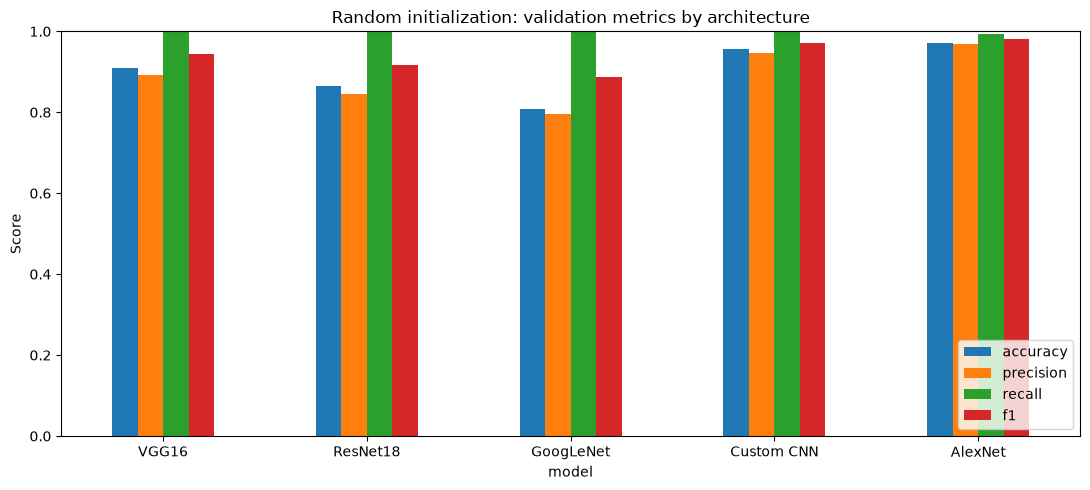

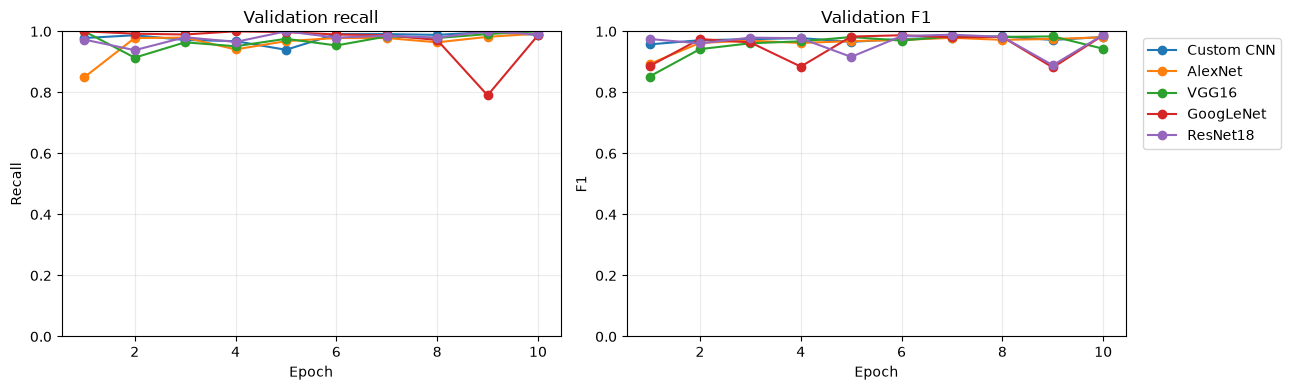

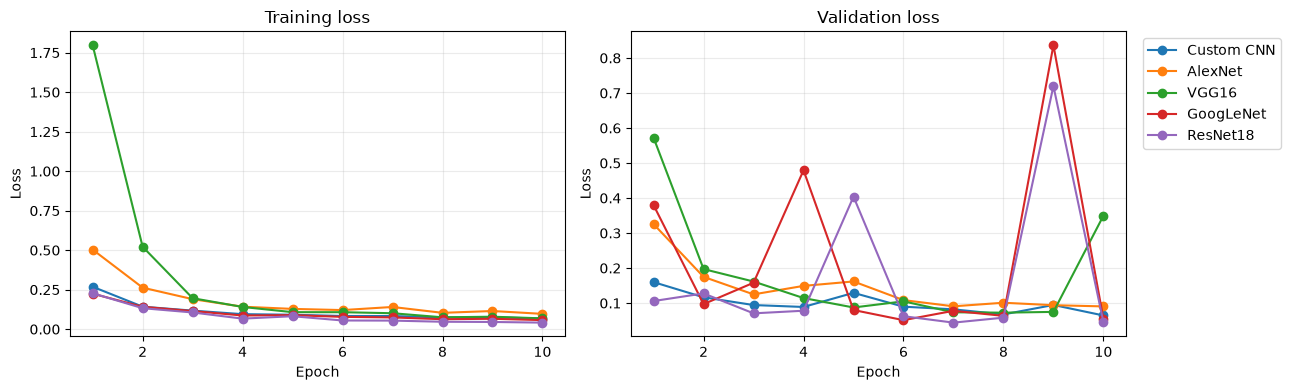

검증 Recall → F1 → Accuracy 기준 최고 구조: VGG16


In [38]:
# 폐렴을 놓치지 않는 것이 중요하므로 Recall을 가장 먼저 비교한다.
# Recall이 같으면 F1, Accuracy 순으로 정렬한다.
architecture_comparison = (
    pd.DataFrame(comparison_rows)
    .set_index('model')
    .sort_values(['recall', 'f1', 'accuracy'], ascending=False)
)
# 파라미터 수와 각 성능 지표를 읽기 쉬운 자릿수로 표시한다.
display(
    architecture_comparison.round({
        'parameters_million': 2, 'accuracy': 4, 'precision': 4,
        'recall': 4, 'f1': 4,
    })
)

# 모델별 최종 validation 지표를 막대그래프로 비교한다.
metric_columns = ['accuracy', 'precision', 'recall', 'f1']
ax = architecture_comparison[metric_columns].plot(
    kind='bar', figsize=(11, 5), ylim=(0, 1), rot=0,
    title='Random initialization: validation metrics by architecture',
)
ax.set_ylabel('Score')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

# epoch가 진행되면서 Recall과 F1이 어떻게 달라졌는지 학습 곡선으로 확인한다.
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
for model_label, history in architecture_histories.items():
    epochs = [row['epoch'] for row in history]
    axes[0].plot(epochs, [row['val_recall'] for row in history], marker='o', label=model_label)
    axes[1].plot(epochs, [row['val_f1'] for row in history], marker='o', label=model_label)
axes[0].set(title='Validation recall', xlabel='Epoch', ylabel='Recall', ylim=(0, 1))
axes[1].set(title='Validation F1', xlabel='Epoch', ylabel='F1', ylim=(0, 1))
for ax in axes:
    ax.grid(alpha=0.25)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
plt.show()

# 모델별 train/validation loss를 나란히 그려 수렴 속도와 과적합 여부를 확인한다.
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
for model_label, history in architecture_histories.items():
    epochs = [row['epoch'] for row in history]
    axes[0].plot(epochs, [row['train_loss'] for row in history], marker='o', label=model_label)
    axes[1].plot(epochs, [row['val_loss'] for row in history], marker='o', label=model_label)
axes[0].set(title='Training loss', xlabel='Epoch', ylabel='Loss')
axes[1].set(title='Validation loss', xlabel='Epoch', ylabel='Loss')
for ax in axes:
    ax.grid(alpha=0.25)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
plt.show()

# 정렬된 표의 첫 번째 모델을 현재 검증 기준의 최고 구조로 선택한다.
best_architecture = architecture_comparison.index[0]
print(f'검증 Recall → F1 → Accuracy 기준 최고 구조: {best_architecture}')